f minor


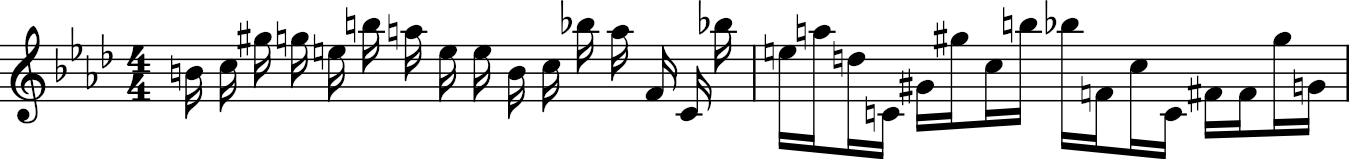

In [1]:
# Generate the synthetic dataset
# New samples have 3 bars and 2 octave pitch range, in 4/4 time signature

# Imports section
import os
import random
from music21 import stream, meter, key, note, converter

# Definition of the path to the results folder
results_folder = "synthetic_dataset"

# Definition of the constant variables
num_bars = 2
time_signature = meter.TimeSignature('4/4')
notes_per_bar = 16
pitch_range = range(60, 84)  # MIDI numbers: C4 (60) to B5 (83)

type_range = ["16th", "eighth", "quarter", "half", "whole"] # needs to be random?

# For getting a random key
keys = ["C", "D", "E", "F", "G", "A", "B", "c", "d", "e", "f", "g", "a", "b"]

num_samples = 1

for sample in range(num_samples):
    new_stream = stream.Stream()
    new_part = stream.Part()

    # Generate random key
    random_key = key.Key(random.choice(keys))
    print(random_key)

    new_stream.append(time_signature)
    new_stream.append(random_key)

    # Create measures
    for i in range(num_bars):
        measure = stream.Measure(number = i+1)

        for j in range(notes_per_bar):
            # Generate random pitch
            pitch = random.choice(pitch_range)

            # Generate random rhythm
            #rhythm = random.choice(type_range)

            # Append new note to the measure
            measure.append(note.Note(pitch, type="16th"))

        new_stream.append(measure)

    new_stream.show()

In [2]:
result_midi_filename = os.path.join(
        results_folder, f"{sample}.midi"
    )
new_stream.write("midi", result_midi_filename)

'synthetic_dataset\\0.midi'

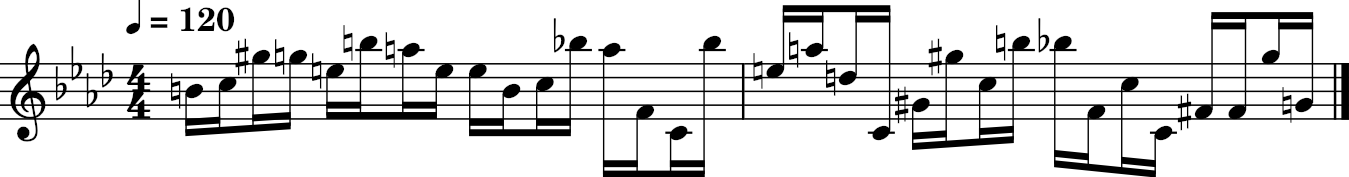

In [3]:
midi_path = "synthetic_dataset/0.midi"
score = converter.parse(midi_path)
score.show()